# Weather Now — Data Science | Entrega 4 (2026)

**Estudo acadêmico de estatísticas agregadas estaduais de violência contra a mulher**. O objetivo é explorar registros oficiais e testar um classificador que distingue taxas **estaduais históricas** de feminicídio acima/abaixo de um limiar didático; **não** estima o risco de uma pessoa, não recomenda decisões de segurança e não substitui avaliação profissional ou autoridade pública.

**Fonte pública (dados reais, não simulados):** Fórum Brasileiro de Segurança Pública (FBSP), *Anuário Brasileiro de Segurança Pública 2026*, **Tabela 21, p. 149 (Brasil e Unidades da Federação, 2024–2025)**.

Link original: https://img1.wsimg.com/blobby/go/ba03c51c-1e7c-44ed-9bd1-fba715830295/Anuario%20Brasileiro%20de%20Seguran%C3%A7a%20P%C3%BAblica%20-2026.pdf

**Autoria:** equipe Weather Now (João Victor Klein e Gustavo Lira). **Divisão individual do pipeline:** a equipe deve preencher a matriz de responsabilidades com as etapas realmente executadas e conseguir explicar o notebook. O código foi preparado com auxílio de IA, registrado em `USO_IA.md`.

**Licença:** não foi confirmada licença específica de redistribuição do Anuário; esta tabela é uma transcrição reduzida e atribuída para estudo acadêmico, e seu uso externo requer verificação das condições do publicador. Nenhuma informação pessoal foi utilizada.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

BASE = Path.cwd()
DADOS = BASE / "dados" / "fbsp_tabela21_2024_2025.csv"
GRAFICOS = BASE / "graficos"
GRAFICOS.mkdir(exist_ok=True)
print("Base:", DADOS.name, "| Local de execução:", BASE)


Base: fbsp_tabela21_2024_2025.csv | Local de execução: /mnt/data/Wheather_Now_Final/data-science


## 1. Coleta, governança e dicionário

A fonte contém registros **agregados** de **27 UFs × 2 anos = 54 linhas**. Transcrição verificada pela soma dos totais da tabela nacional: homicídios de mulheres 3.728 (2024) e 3.539 (2025); feminicídios 1.504 (2024) e 1.571 (2025). **Taxas são por 100 mil mulheres**, e os números estão sujeitos a revisão pelos órgãos responsáveis. A categoria de feminicídio é um subconjunto dos homicídios de mulheres, então essas variáveis são correlacionadas por definição.

Campos: `uf` unidade federativa; `ano` ano de registro; `homicidios_mulheres` número absoluto; `taxa_homicidios_mulheres` taxa estadual; `feminicidios` número absoluto; `taxa_feminicidios` taxa estadual. Os dados não contêm nomes, endereços nem eventos individuais.

In [2]:
df = pd.read_csv(DADOS, encoding="utf-8")
colunas_esperadas = {"uf", "ano", "homicidios_mulheres", "taxa_homicidios_mulheres", "feminicidios", "taxa_feminicidios"}
assert set(df.columns) == colunas_esperadas
assert len(df) == 54 and df.uf.nunique() == 27 and set(df.ano) == {2024, 2025}
assert df.groupby("ano")[["homicidios_mulheres", "feminicidios"]].sum().to_dict() == {
    "homicidios_mulheres": {2024: 3728, 2025: 3539},
    "feminicidios": {2024: 1504, 2025: 1571},
}, "A transcrição não coincide com os totais da publicação"
print("Primeiros registros:")
display(df.head(8))
print("Total de UFs:", df.uf.nunique(), "| Registros:", len(df))


Primeiros registros:


,uf,ano,homicidios_mulheres,taxa_homicidios_mulheres,feminicidios,taxa_feminicidios
0,Acre,2024,28,6.4,8,1.8
1,Acre,2025,21,4.8,14,3.2
2,Alagoas,2024,73,4.4,22,1.3
3,Alagoas,2025,94,5.6,30,1.8
4,Amapá,2024,6,1.5,2,0.5
5,Amapá,2025,18,4.5,9,2.2
6,Amazonas,2024,77,3.6,29,1.4
7,Amazonas,2025,62,2.9,20,0.9


Total de UFs: 27 | Registros: 54


## 2. Qualidade, limpeza e privacidade

Os valores do CSV foram transcritos de tabela publicada e **não foram gerados por IA**. A etapa verifica campos ausentes, duplicatas, domínio das taxas e chaves únicas; valores ausentes em dados oficiais não devem ser inventados. A documentação registra que a publicação pode retificar valores após novas consolidações.

In [3]:
print("Valores ausentes por coluna:\n", df.isna().sum().to_string())
print("Linhas repetidas:", int(df.duplicated().sum()))
print("Chaves uf/ano repetidas:", int(df.duplicated(["uf", "ano"]).sum()))
assert df.isna().sum().sum() == 0 and not df.duplicated(["uf", "ano"]).any()
assert df[["homicidios_mulheres", "taxa_homicidios_mulheres", "feminicidios", "taxa_feminicidios"]].ge(0).all().all()
assert (df.feminicidios <= df.homicidios_mulheres).all()
df = df.drop_duplicates(subset=["uf", "ano"]).sort_values(["uf", "ano"]).reset_index(drop=True)
print("Amostras após limpeza:", len(df))


Valores ausentes por coluna:
 uf                          0
ano                         0
homicidios_mulheres         0
taxa_homicidios_mulheres    0
feminicidios                0
taxa_feminicidios           0
Linhas repetidas: 0
Chaves uf/ano repetidas: 0
Amostras após limpeza: 54


## 3. Análise exploratória (EDA)

Medidas de tendência central, dispersão e distribuição de frequências para as taxas publicadas. A comparação direta entre estados não identifica causas da violência nem o risco de vítimas específicas.

In [4]:
print("Descrição estatística por ano (taxas por 100 mil mulheres):")
display(df.groupby("ano")[["taxa_homicidios_mulheres", "taxa_feminicidios"]].agg(["mean", "median", "std", "min", "max"]).round(2))
print("Frequências da taxa de feminicídio (cortes descritivos):")
faixas = pd.cut(df.taxa_feminicidios, bins=[0, 1, 1.5, 2, np.inf], include_lowest=True)
display(faixas.value_counts().sort_index().rename("quantidade").to_frame())
print("UFs com maior taxa observada em 2025:")
display(df[df.ano.eq(2025)].nlargest(8, "taxa_feminicidios")[["uf", "taxa_feminicidios", "feminicidios"]])


Descrição estatística por ano (taxas por 100 mil mulheres):


taxa_homicidios_mulheres                    ... taxa_feminicidios                
                         mean median   std  min  ...            median   std  min  max
ano                                              ...                                  
2024                     3.79    4.1  1.32  1.5  ...               1.4  0.48  0.5  2.5
2025                     3.82    3.7  1.17  1.8  ...               1.6  0.60  0.9  3.2

[2 rows x 10 columns]

Frequências da taxa de feminicídio (cortes descritivos):


,quantidade
taxa_feminicidios,
"(-0.001, 1.0]",5
"(1.0, 1.5]",22
"(1.5, 2.0]",17
"(2.0, inf]",10


UFs com maior taxa observada em 2025:


,uf,taxa_feminicidios,feminicidios
1,Acre,3.2,14
43,Rondônia,2.9,25
21,Mato Grosso,2.7,53
23,Mato Grosso do Sul,2.6,39
53,Tocantins,2.5,20
5,Amapá,2.2,9
35,Piauí,2.1,37
13,Distrito Federal,1.9,29


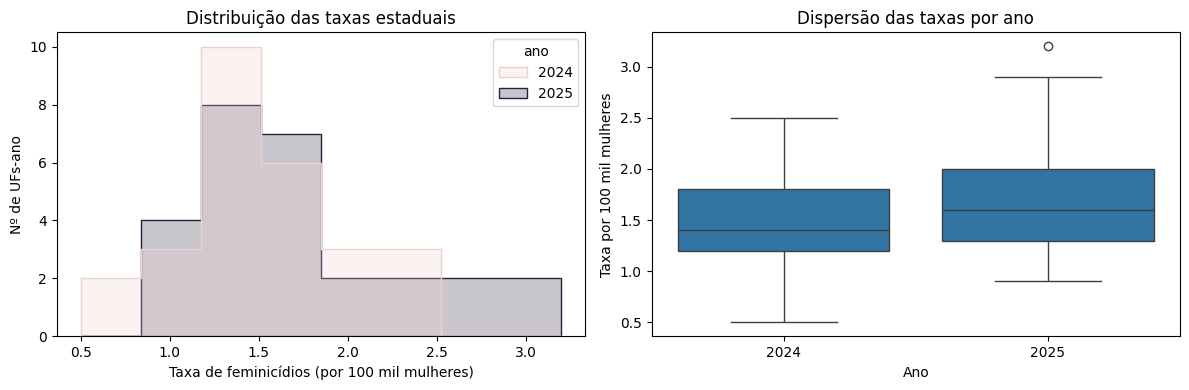

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="taxa_feminicidios", hue="ano", element="step", stat="count", bins=8, ax=axes[0])
axes[0].set(title="Distribuição das taxas estaduais", xlabel="Taxa de feminicídios (por 100 mil mulheres)", ylabel="Nº de UFs-ano")
sns.boxplot(data=df, x="ano", y="taxa_feminicidios", ax=axes[1])
axes[1].set(title="Dispersão das taxas por ano", xlabel="Ano", ylabel="Taxa por 100 mil mulheres")
plt.tight_layout()
plt.savefig(GRAFICOS / "eda_taxas.png", dpi=135)
plt.show()


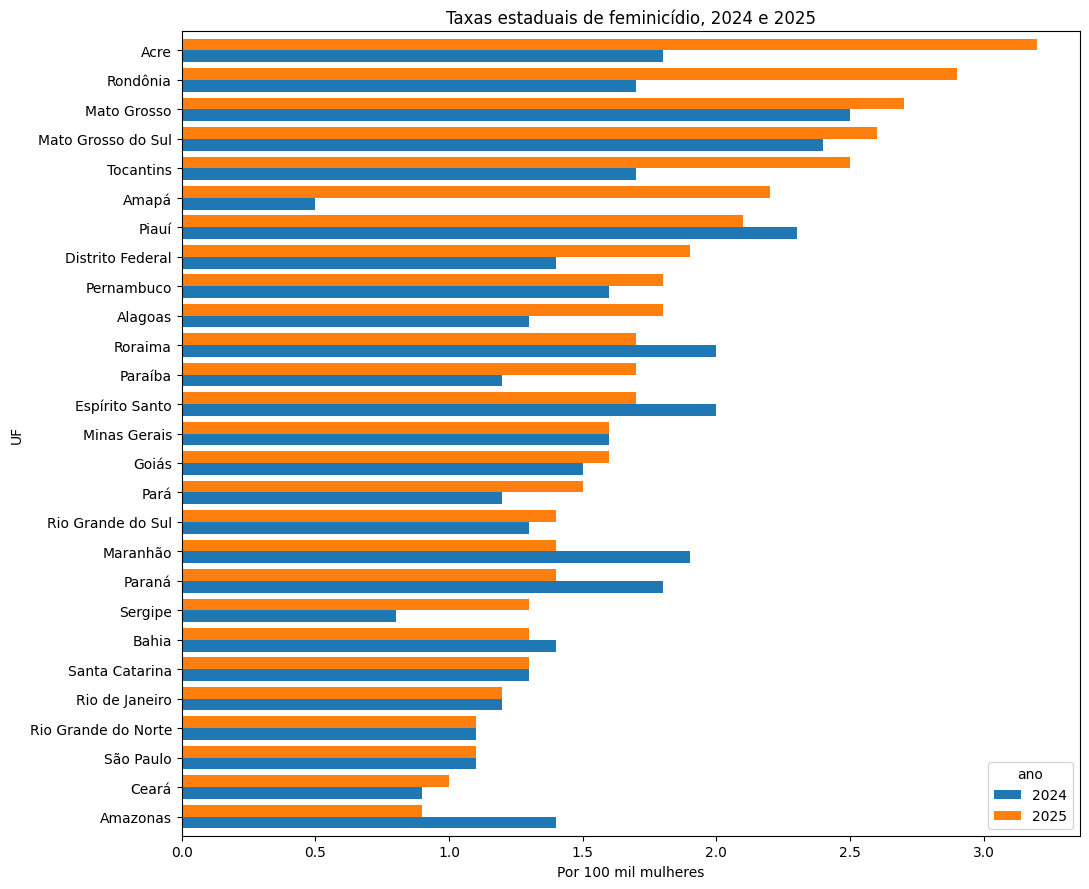

In [6]:
tabela = df.pivot(index="uf", columns="ano", values="taxa_feminicidios").sort_values(2025)
ax = tabela.plot(kind="barh", figsize=(11, 9), width=.8)
ax.set(title="Taxas estaduais de feminicídio, 2024 e 2025", xlabel="Por 100 mil mulheres", ylabel="UF")
plt.tight_layout()
plt.savefig(GRAFICOS / "comparativo_ufs.png", dpi=140)
plt.show()


## 4. Problema de classificação (prova de conceito)

**Alvo didático**: classificar uma observação de UF/ano como taxa registrada de feminicídios **≥ 1,5 por 100 mil mulheres** (`1`) versus **abaixo de 1,5** (`0`). O ponto de corte é **arbitrário**, apenas para o exercício — **não** é limiar de risco oficial, não representa nível de urgência ou diagnóstico.

Preditores: ano, número de homicídios de mulheres e taxa de homicídios de mulheres, todos agregados. **Os números/taxas de feminicídios, bem como a UF, não entram nas variáveis preditoras.** A taxa de homicídios inclui feminicídios; portanto, há sobreposição conceitual, e o uso do modelo é apenas pedagógico, sem alegação de previsão prospectiva. Separação por UF: os mesmos estados não aparecem simultaneamente em treino e teste; na validação cruzada, os grupos também são segregados.

Modelo: regressão logística padronizada, com pesos balanceados. Comparação com baseline que prevê sempre a classe majoritária.

In [7]:
LIMIAR_DIDATICO = 1.5
FEATURES = ["ano", "homicidios_mulheres", "taxa_homicidios_mulheres"]
X = df[FEATURES].copy()
y = (df["taxa_feminicidios"] >= LIMIAR_DIDATICO).astype(int)
grupos = df["uf"]
separador = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=42)
idx_treino, idx_teste = next(separador.split(X, y, groups=grupos))
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
g_treino, g_teste = grupos.iloc[idx_treino], grupos.iloc[idx_teste]
assert set(g_treino).isdisjoint(set(g_teste))
print("Distribuição geral das classes:", y.value_counts().sort_index().to_dict())
print("Treino:", len(X_treino), "linhas de", g_treino.nunique(), "UFs")
print("Teste:", len(X_teste), "linhas de", g_teste.nunique(), "UFs inéditas")


Distribuição geral das classes: {0: 25, 1: 29}
Treino: 40 linhas de 20 UFs
Teste: 14 linhas de 7 UFs inéditas


Métricas em UFs reservadas para teste:


,acurácia,precisão,recall,f1
Modelo,0.571,0.875,0.583,0.7
Baseline,0.143,0.000,0.000,0.0


Relatório por classe:
               precision    recall  f1-score   support

           0       0.17      0.50      0.25         2
           1       0.88      0.58      0.70        12

    accuracy                           0.57        14
   macro avg       0.52      0.54      0.47        14
weighted avg       0.77      0.57      0.64        14

Matriz de confusão:
 [[1 1]
 [5 7]]


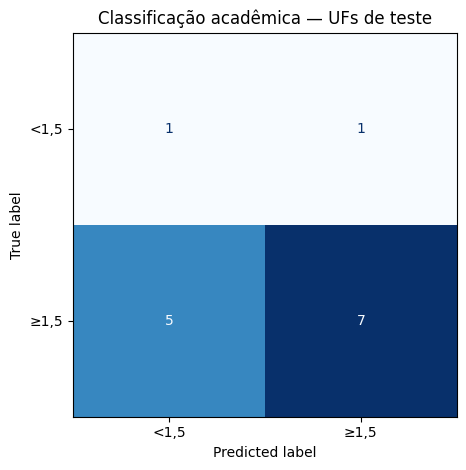

In [8]:
modelo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
modelo.fit(X_treino, y_treino)
pred = modelo.predict(X_teste)
baseline = DummyClassifier(strategy="most_frequent").fit(X_treino, y_treino)
pred_baseline = baseline.predict(X_teste)

def metricas(y_real, y_previsto):
    return {"acurácia": accuracy_score(y_real, y_previsto),
            "precisão": precision_score(y_real, y_previsto, zero_division=0),
            "recall": recall_score(y_real, y_previsto, zero_division=0),
            "f1": f1_score(y_real, y_previsto, zero_division=0)}

res = pd.DataFrame({"Modelo": metricas(y_teste, pred), "Baseline": metricas(y_teste, pred_baseline)}).T
print("Métricas em UFs reservadas para teste:")
display(res.round(3))
print("Relatório por classe:\n", classification_report(y_teste, pred, labels=[0, 1], zero_division=0))
print("Matriz de confusão:\n", confusion_matrix(y_teste, pred, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(y_teste, pred, labels=[0, 1], display_labels=["<1,5", "≥1,5"], cmap="Blues", colorbar=False)
plt.title("Classificação acadêmica — UFs de teste")
plt.tight_layout()
plt.savefig(GRAFICOS / "matriz_confusao.png", dpi=135)
plt.show()


## 5. Validação cruzada com grupos

GroupKFold divide **por UF**, para que nenhum estado apareça em duas partes de um mesmo fold. Isso fornece uma estimativa mais cautelosa do que embaralhar registros dos mesmos estados. A amostra possui apenas 27 UFs, cada uma com dois anos; as métricas têm grande incerteza e não devem ser generalizadas.

In [9]:
cv = GroupKFold(n_splits=4)
resultados_cv = cross_validate(
    modelo, X_treino, y_treino, groups=g_treino, cv=cv,
    scoring={"acc": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"},
    error_score="raise",
)
cv_df = pd.DataFrame({k.replace("test_", ""): v for k, v in resultados_cv.items() if k.startswith("test_")})
print("Resultados de validação cruzada (grupos = UFs):")
display(cv_df.round(3))
print("Média das métricas por fold:\n", cv_df.mean().round(3).to_string())


Resultados de validação cruzada (grupos = UFs):


,acc,precision,recall,f1
0,0.5,0.80,0.500,0.615
1,0.9,0.75,1.000,0.857
2,0.9,0.75,1.000,0.857
3,0.4,0.20,0.333,0.250


Média das métricas por fold:
 acc          0.675
precision    0.625
recall       0.708
f1           0.645


## 6. Integração: artefato consumido pela API e pelo aplicativo

Para a demonstração acadêmica, o pipeline ajusta uma **nova cópia** do mesmo algoritmo a todos os 54 registros, exclusivamente para produzir as categorias exibidas por UF em **2025**. Isso **não é o conjunto de teste** e não altera as métricas anteriores, que foram calculadas antes dessa nova etapa. A classificação é relativa a registros históricos e não pode ser usada como orientação de segurança pessoal.

O arquivo `../backend/data-science/indicadores.json` é gerado automaticamente a partir do CSV real e consumido por `GET /indicadores` na API Express, que alimenta a tela **Dados / Estatísticas** da área reservada.

In [10]:
modelo_demo = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))
modelo_demo.fit(X, y)
recortes = df[df.ano.eq(2025)].copy().sort_values("uf")
prob = modelo_demo.predict_proba(recortes[FEATURES])[:, 1]
classes = modelo_demo.predict(recortes[FEATURES])
indicadores = []
for (_, linha), p, cl in zip(recortes.iterrows(), prob, classes):
    indicadores.append({
      "uf": linha["uf"], "ano": 2025,
      "homicidios_mulheres": int(linha["homicidios_mulheres"]),
      "taxa_homicidios_mulheres": float(linha["taxa_homicidios_mulheres"]),
      "feminicidios": int(linha["feminicidios"]),
      "taxa_feminicidios_observada": float(linha["taxa_feminicidios"]),
      "categoria_estimada": "Faixa histórica ≥ 1,5" if cl == 1 else "Faixa histórica < 1,5",
    })
saida = {
    "titulo": "Indicador acadêmico por UF — 2025",
    "fonte": "FBSP, Anuário Brasileiro de Segurança Pública 2026, Tabela 21, p. 149",
    "fonte_url": "https://img1.wsimg.com/blobby/go/ba03c51c-1e7c-44ed-9bd1-fba715830295/Anuario%20Brasileiro%20de%20Seguran%C3%A7a%20P%C3%BAblica%20-2026.pdf",
    "ano": 2025,
    "aviso": "Estimativa estatística acadêmica sobre dados históricos agregados. NÃO avalia o risco individual e NÃO substitui atendimento profissional, policial ou jurídico.",
    "limiar_didatico": 1.5,
    "metodologia": "Regressão logística; previsão de categoria de taxa histórica por UF com dados agregados; treino final para exibição após avaliação em UFs separadas.",
    "indicadores": indicadores,
}
DESTINO = BASE.parent / "backend" / "data-science" / "indicadores.json"
DESTINO.parent.mkdir(parents=True, exist_ok=True)
DESTINO.write_text(json.dumps(saida, indent=2, ensure_ascii=False), encoding="utf-8")
print("Artefato exportado:", DESTINO.relative_to(BASE.parent), "| UFs:", len(indicadores))
print("Exemplo Paraná:")
print(next(i for i in indicadores if i["uf"] == "Paraná"))


Artefato exportado: backend/data-science/indicadores.json | UFs: 27
Exemplo Paraná:
{'uf': 'Paraná', 'ano': 2025, 'homicidios_mulheres': 188, 'taxa_homicidios_mulheres': 3.1, 'feminicidios': 87, 'taxa_feminicidios_observada': 1.4, 'categoria_estimada': 'Faixa histórica < 1,5'}


## 7. Conclusões, limitações e ética

- O conjunto representa somente dois anos e 27 unidades federativas. Ele é agregado, pequeno e inclui variações de registro entre estados; métricas não sustentam uso operacional.
- O ponto de corte de 1,5 é uma escolha didática, não uma classificação oficial de segurança.
- `taxa_homicidios_mulheres` inclui os casos de feminicídio; por isso, mesmo sem usar diretamente o alvo como feature, a interpretação pode conter sobreposição conceitual. O modelo não prediz episódios futuros e não deve decidir ações de proteção.
- O aplicativo apresenta o **dado observado** ao lado de uma **categoria estimada** e avisa que é análise acadêmica; não se deve associar resultados a contatos, ocorrências ou usuárias.
- Recursos **reais** de emergência no aplicativo: Ligue 180 e 190. O botão SOS interno só grava alertas demonstrativos.
- **Divisão de responsabilidades:** preencher no arquivo `docs/matriz-responsabilidades.md`, conforme trabalho individual de cada estudante.
